<a href="https://colab.research.google.com/github/Faheemmundoli/house-price-prediction-ml/blob/main/house_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Faheem M 2427010572

# Lab 15: Mini Project - House Price Prediction using Machine Learning

### Problem Statement:
To predict the median house value of a California district from features such as income, house age, number of rooms and location, and to find which model predicts best.

### Objectives:
1. Explore the data and find the features that affect house prices.
2. Train Linear Regression, Decision Tree and Random Forest models.
3. Compare the models using MAE, RMSE and R-squared.
4. Tune the best model and find the most important features.

## 1. Dataset :
The California Housing dataset has 20,640 districts and 8 features. The target MedHouseVal is the median house value in units of $100,000.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = fetch_california_housing(as_frame=True).frame
print(df.shape)
print("Missing values:", df.isna().sum().sum())
df.describe().round(2)

(20640, 9)
Missing values: 0


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


## 2. Exploratory Data Analysis :
The histogram shows how house values are distributed. The heatmap shows which features are related to the house value.

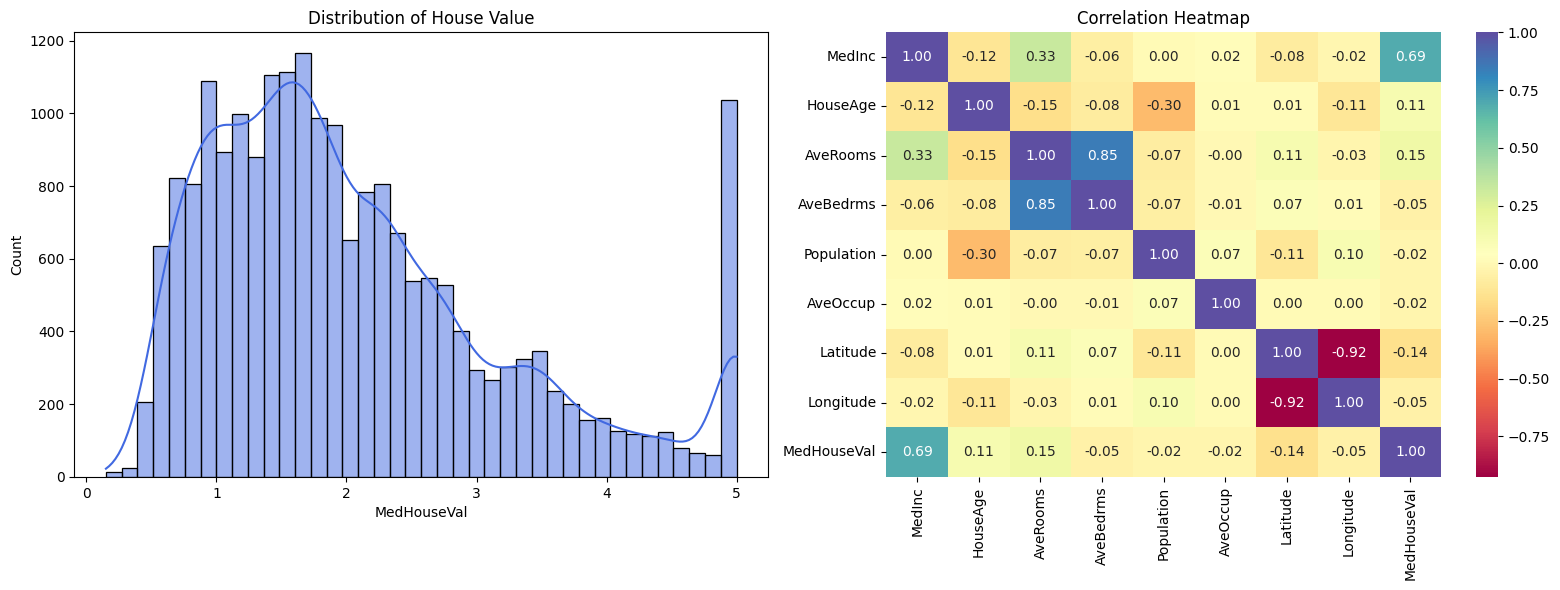

In [2]:
plt.figure(figsize=(16, 6))

plt.subplot(1, 2, 1)
sns.histplot(df['MedHouseVal'], bins=40, kde=True, color='royalblue')
plt.title('Distribution of House Value')

plt.subplot(1, 2, 2)
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='Spectral')
plt.title('Correlation Heatmap')

plt.tight_layout()
plt.show()

## 3. Data Preparation :
The data is split 80% for training and 20% for testing. The features are standardized so that they are on the same scale.

In [3]:
X = df.drop('MedHouseVal', axis=1)
y = df['MedHouseVal']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

## 4. Model Training and Comparison :
Three regression models are trained on the same data. MAE is the average error, RMSE punishes big errors more, and R-squared shows how much of the variation in house value the model explains. All errors are in units of $100,000.

In [4]:
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(max_depth=8, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
}

rows, preds = [], {}
for name, model in models.items():
    model.fit(X_train_s, y_train)
    p = model.predict(X_test_s)
    preds[name] = p
    rows.append([name, mean_absolute_error(y_test, p), np.sqrt(mean_squared_error(y_test, p)), r2_score(y_test, p)])

results = pd.DataFrame(rows, columns=['Model', 'MAE', 'RMSE', 'R2']).round(3)
results

,Model,MAE,RMSE,R2
0,Linear Regression,0.533,0.746,0.576
1,Decision Tree,0.448,0.650,0.678
2,Random Forest,0.346,0.523,0.791


## 5. Actual vs Predicted :
Each dot is a test district. The closer the dots are to the dashed line, the better the predictions.

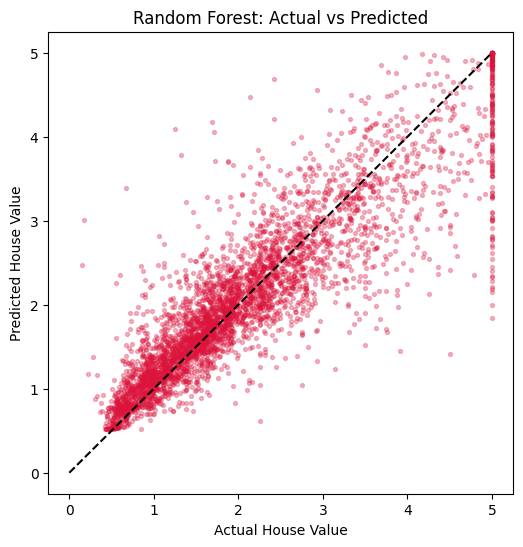

In [5]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, preds['Random Forest'], alpha=0.3, s=8, color='crimson')
plt.plot([0, 5], [0, 5], 'k--')
plt.title('Random Forest: Actual vs Predicted')
plt.xlabel('Actual House Value')
plt.ylabel('Predicted House Value')
plt.show()

## 6. Hyperparameter Tuning :
Random Search tries a few random combinations of Random Forest settings using 3-fold cross-validation and keeps the best one.

In [6]:
param_dist = {'n_estimators': [50, 100],
              'max_depth': [8, 12, 16, None],
              'min_samples_leaf': [1, 2, 4]}

search = RandomizedSearchCV(RandomForestRegressor(random_state=42, n_jobs=-1),
                            param_dist, n_iter=4, cv=3, scoring='r2', random_state=42)
search.fit(X_train_s, y_train)

print("Best parameters:", search.best_params_)
print("Best CV R2     :", round(search.best_score_, 3))
print("Test R2        :", round(search.score(X_test_s, y_test), 3))

Best parameters: {'n_estimators': 50, 'min_samples_leaf': 1, 'max_depth': None}
Best CV R2     : 0.798
Test R2        : 0.804


## 7. Feature Importance :
The tuned Random Forest shows how much each feature helped in predicting the house value.

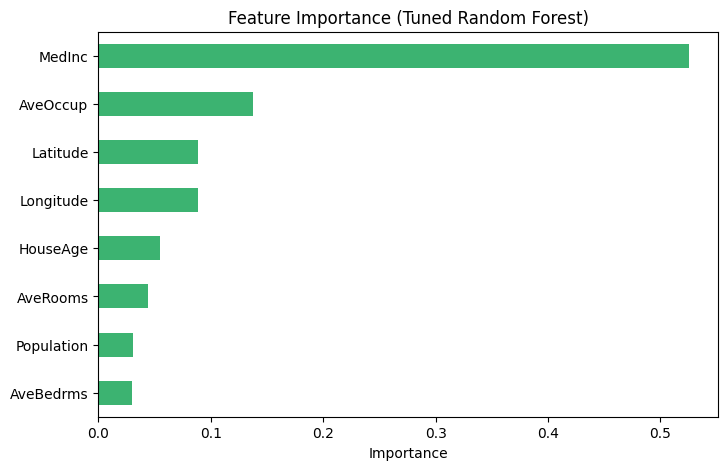

In [7]:
best = search.best_estimator_
pd.Series(best.feature_importances_, index=X.columns).sort_values().plot(
    kind='barh', color='mediumseagreen', figsize=(8, 5))
plt.title('Feature Importance (Tuned Random Forest)')
plt.xlabel('Importance')
plt.show()

## 8. Conclusion :
Random Forest gave the best results, with the highest R-squared and the lowest error, followed by the Decision Tree, and Linear Regression was the weakest. Median income was the most important feature for predicting house value. (Write your own R-squared and RMSE values from the results table here.)